# Alzheimer's Detection: AdaBoost vs. Gradient Boosting — results analysis
This notebook rebuilds every table and figure in `paper.md` from the test-set results reported in the project (class counts and the two confusion matrices). It needs no raw data. The cell below also **verifies** that the confusion matrices reproduce the report's Tables I and II.

The original model-training notebook is separate (see README).

## 1. Setup

In [1]:
import json
from math import sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", font_scale=0.75)
COL = {"AdaBoost": "#4C6EF5", "Gradient Boosting": "#1B9E77"}

## 2. Reported results and consistency check

In [2]:
# ---- Reported results (from the project PDF) ----
CLASS_COUNTS = {"No Alzheimer (0)": 1389, "Alzheimer (1)": 760}          # Fig. 1 of the project
CM = {  # rows = true [No Alzheimer, Alzheimer], cols = predicted
    "AdaBoost":          np.array([[261, 16], [22, 131]]),               # Fig. 3
    "Gradient Boosting": np.array([[271, 6],  [12, 141]]),               # Fig. 4
}
REPORTED = {  # Tables I and II of the project (precision, recall, F1) for sanity checking
    "AdaBoost": {"No Alzheimer": (0.92, 0.94, 0.93), "Alzheimer": (0.89, 0.86, 0.87), "accuracy": 0.91},
    "Gradient Boosting": {"No Alzheimer": (0.96, 0.98, 0.97), "Alzheimer": (0.96, 0.92, 0.94), "accuracy": 0.96},
}

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def metrics(cm):
    tn, fp, fn, tp = cm.ravel(); n = cm.sum()
    out = dict(n=int(n), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp),
               accuracy=(tn + tp) / n,
               prec_no=tn / (tn + fn), rec_no=tn / (tn + fp), f1_no=2 * tn / (2 * tn + fp + fn),
               prec_ad=tp / (tp + fp), rec_ad=tp / (tp + fn), f1_ad=2 * tp / (2 * tp + fp + fn),
               specificity=tn / (tn + fp), sensitivity=tp / (tp + fn),
               errors=int(fp + fn),
               miss_rate_ad=fn / (tp + fn))
    out["balanced_acc"] = (out["sensitivity"] + out["specificity"]) / 2
    out["macro_f1"] = (out["f1_no"] + out["f1_ad"]) / 2
    out["mcc"] = (tp * tn - fp * fn) / sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    out["acc_ci"] = wilson(tn + tp, n)
    out["sens_ci"] = wilson(tp, tp + fn)
    out["spec_ci"] = wilson(tn, tn + fp)
    return out

M = {k: metrics(v) for k, v in CM.items()}
# Consistency check against the tables printed in the project PDF
for k, rep in REPORTED.items():
    m = M[k]
    got = {"No Alzheimer": (m["prec_no"], m["rec_no"], m["f1_no"]), "Alzheimer": (m["prec_ad"], m["rec_ad"], m["f1_ad"])}
    for cls in ["No Alzheimer", "Alzheimer"]:
        assert all(abs(a - b) <= 0.0051 for a, b in zip(got[cls], rep[cls])), (k, cls, got[cls], rep[cls])
    assert abs(m["accuracy"] - rep["accuracy"]) <= 0.0051
baseline_acc = 277 / 430
print("Reported tables match the confusion matrices.")
print('Reported tables match the confusion matrices.')

Reported tables match the confusion matrices.
Reported tables match the confusion matrices.


## 3. Derived metrics table (Table 2 of the paper)

In [3]:
# ---- Tables ----
rows = []
for k, m in M.items():
    rows.append({"Model": k, "Accuracy": m["accuracy"], "Macro F1": m["macro_f1"], "Balanced accuracy": m["balanced_acc"], "MCC": m["mcc"],
                 "Alzheimer precision": m["prec_ad"], "Alzheimer recall (sensitivity)": m["sensitivity"],
                 "No-Alzheimer recall (specificity)": m["specificity"], "FP": m["FP"], "FN": m["FN"], "Total errors": m["errors"]})
tab = pd.DataFrame(rows).set_index("Model")
tab.round(3).to_csv("results/test_metrics.csv")
json.dump({k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in m.items()} for k, m in M.items()} |
          {"majority_baseline_accuracy": baseline_acc, "class_counts": CLASS_COUNTS},
          open("results/reported_results.json", "w"), indent=2, default=float)
tab.round(3)

,Accuracy,Macro F1,Balanced accuracy,MCC,Alzheimer precision,Alzheimer recall (sensitivity),No-Alzheimer recall (specificity),FP,FN,Total errors
Model,,,,,,,,,,
AdaBoost,0.912,0.903,0.899,0.806,0.891,0.856,0.942,16,22,38
Gradient Boosting,0.958,0.954,0.950,0.908,0.959,0.922,0.978,6,12,18


## 4. Figures

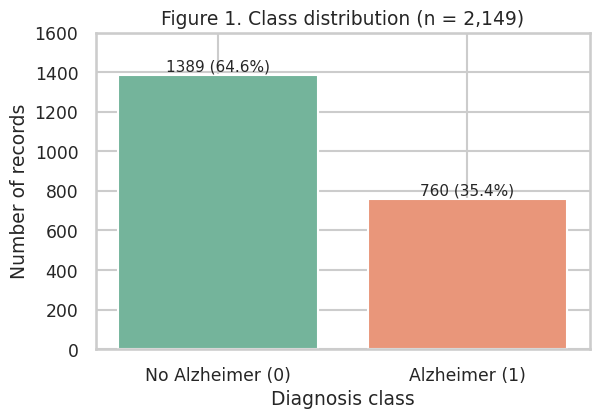

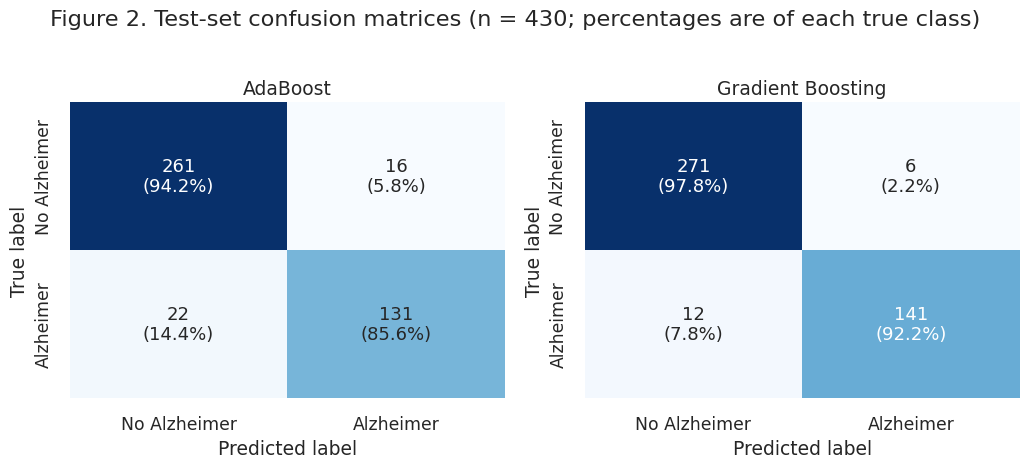

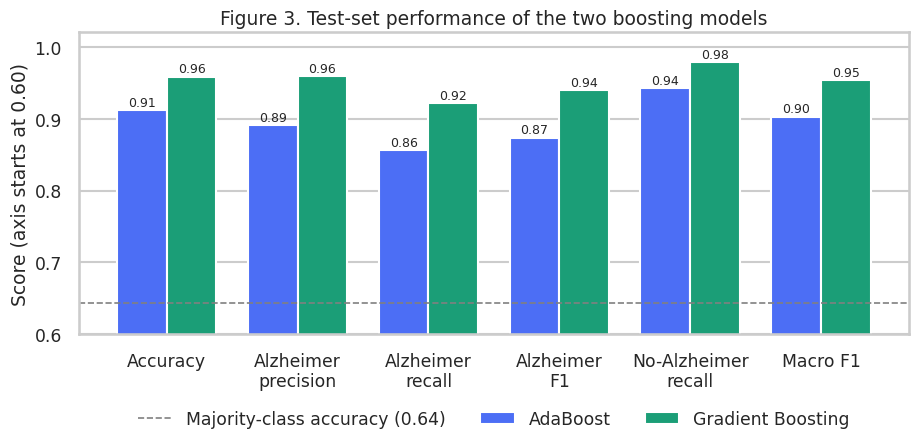

In [4]:
# ---- Figure 1: class distribution ----
fig, ax = plt.subplots(figsize=(6.2, 4.4))
names, vals = list(CLASS_COUNTS), list(CLASS_COUNTS.values())
bars = ax.bar(names, vals, color=["#74B49B", "#E9967A"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v} ({v / sum(vals):.1%})", ha="center", fontsize=11)
ax.set_ylabel("Number of records"); ax.set_xlabel("Diagnosis class"); ax.set_ylim(0, 1600)
ax.set_title("Figure 1. Class distribution (n = 2,149)")
fig.tight_layout(); fig.savefig("figures/fig1_class_distribution.png", dpi=200); plt.show()

# ---- Figure 2: confusion matrices ----
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
for ax, (k, cm) in zip(axes, CM.items()):
    pct = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 13},
                xticklabels=["No Alzheimer", "Alzheimer"], yticklabels=["No Alzheimer", "Alzheimer"])
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(k)
fig.suptitle("Figure 2. Test-set confusion matrices (n = 430; percentages are of each true class)", y=1.02)
fig.tight_layout(); fig.savefig("figures/fig2_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- Figure 3: metric comparison ----
labels = ["Accuracy", "Alzheimer\nprecision", "Alzheimer\nrecall", "Alzheimer\nF1", "No-Alzheimer\nrecall", "Macro F1"]
keys = ["accuracy", "prec_ad", "rec_ad", "f1_ad", "rec_no", "macro_f1"]
x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, (k, m) in enumerate(M.items()):
    v = [m[kk] for kk in keys]
    bars = ax.bar(x + (i - 0.5) * w, v, w, label=k, color=COL[k])
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.006, f"{val:.2f}", ha="center", fontsize=9)
ax.axhline(baseline_acc, color="gray", ls="--", lw=1.2, label=f"Majority-class accuracy ({baseline_acc:.2f})")
ax.grid(axis="x", visible=False)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0.6, 1.02); ax.set_ylabel("Score (axis starts at 0.60)")
ax.set_title("Figure 3. Test-set performance of the two boosting models")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout(); fig.savefig("figures/fig3_metric_comparison.png", dpi=200, bbox_inches="tight"); plt.show()